# Thực nghiệm đối chứng: chia 60/20/20 (thiết kế giữa kỳ) vs 80/20 + 5-fold CV (thiết kế cuối kỳ)

**Nhóm 15 – DRRF.** Notebook này kiểm chứng *vì sao nhóm đổi cách chia dữ liệu ở Tầng 2*.

- **Cách A – 60/20/20 (bài giữa kỳ):** Train 144 · Validation 48 · Test 48. Tinh chỉnh và chọn mô hình trên Validation, rồi đánh giá trên Test.
- **Cách B – 80/20 + 5-fold CV lặp 10 lần (bài cuối kỳ):** Train 192 dùng cho CV · Test 48.

Câu hỏi kiểm chứng: **nếu chỉ chia một lần, kết quả có phụ thuộc vào "may rủi" của lần chia không?**
Để trả lời, nhóm chạy cách A với seed 42, rồi lặp lại toàn bộ quy trình 60/20/20 với 200 seed khác nhau.

Cách chạy: đặt notebook cùng thư mục với `dataset_cement_cust.xlsx` → `Run All` (khoảng 3–6 phút).
Hình được lưu vào thư mục `hinh_anh_60_20_20/`, bảng kết quả vào `ket_qua_60_20_20/`.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.metrics import mean_squared_error, r2_score
warnings.filterwarnings("ignore")

SEED = 42
DATA = "dataset_cement_cust.xlsx"
if not os.path.exists(DATA):            # chạy trên Google Colab: tải file lên
    from google.colab import files
    files.upload()
FIG_DIR, OUT_DIR = "hinh_anh_60_20_20", "ket_qua_60_20_20"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    print("Đã lưu:", f"{FIG_DIR}/{name}.png")

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

df = pd.read_excel(DATA)
print(df.shape)

(240, 21)


## Bước 1 – Tái tạo nhãn Rebate (giống hệt mục 5.2–5.4)

Phần này lặp lại đúng pipeline chính thức (11 biến, K-Means k = 2, AHP, quy đổi P10–P90 theo cụm) để hai cách chia được so sánh trên **cùng một nhãn**.

In [2]:
TARGET_RAW = "Muc_rebate_hien_tai_VND_tan"
cand = [c for c in df.select_dtypes("number").columns if c != TARGET_RAW]
drop = ["So_diem_ban", "Gia_ban_trung_binh_NPP_VND_tan", "Bien_loi_nhuan_gop_NPP_pct",
        "Gia_TB_thi_truong_khu_vuc_VND_tan", "Bien_loi_nhuan_TB_doi_thu_pct"]
FEATS11 = [c for c in cand if c not in drop]
assert len(FEATS11) == 11

# Tầng 1 – K-Means k = 2
STRAT6 = ["Doanh_so_12_thang_tan", "Profitability_Gap_pct", "Cuong_do_canh_tranh_1_5",
          "Diem_du_an_ha_tang_khu_vuc_1_5", "Share_of_Wallet_pct", "Tang_truong_YoY_pct"]
lab = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit_predict(StandardScaler().fit_transform(df[STRAT6]))
need_c = int(df.groupby(lab)["Profitability_Gap_pct"].mean().idxmin())
df["Cluster_ID"] = np.where(lab == need_c, 1, 0)

# Chuẩn hóa theo hướng (bản A – "need") + AHP
CRIT = ["Profitability_Gap_pct", "Diem_du_an_ha_tang_khu_vuc_1_5", "Cuong_do_canh_tranh_1_5",
        "Share_of_Wallet_pct", "Doanh_so_12_thang_tan", "Price_Index", "Ty_le_cong_no_qua_han_pct"]
DIRS = dict(zip(CRIT, ["cost", "benefit", "benefit", "benefit", "benefit", "ideal", "cost"]))
TOL = float(np.round((df["Price_Index"] - 1).abs().quantile(0.95), 3))
def normalize(s, d):
    if d == "benefit": return (s - s.min()) / (s.max() - s.min())
    if d == "cost":    return (s.max() - s) / (s.max() - s.min())
    return np.clip(1 - (s - 1).abs() / TOL, 0, 1)
names = ["PG", "GR", "CT", "SOW", "DS", "PI", "CN"]
upper = {("PG","GR"):2,("PG","CT"):2,("PG","SOW"):2,("PG","DS"):3,("PG","PI"):6,("PG","CN"):6,
         ("GR","CT"):1,("GR","SOW"):1,("GR","DS"):2,("GR","PI"):4,("GR","CN"):4,
         ("CT","SOW"):1,("CT","DS"):2,("CT","PI"):3,("CT","CN"):3,
         ("SOW","DS"):2,("SOW","PI"):3,("SOW","CN"):3,("DS","PI"):2,("DS","CN"):2,("PI","CN"):1}
M = np.ones((7, 7))
for (a, b), v in upper.items():
    i, j = names.index(a), names.index(b); M[i, j], M[j, i] = v, 1 / v
ev, evec = np.linalg.eig(M); k = int(np.argmax(ev.real))
w = np.abs(evec[:, k].real); w /= w.sum()
df["Rebate_Score"] = sum(normalize(df[c], DIRS[c]) * wi for c, wi in zip(CRIT, w))

lbl = pd.Series(index=df.index, dtype=float)
for c, g in df.groupby("Cluster_ID"):
    lo, hi = g[TARGET_RAW].quantile(0.10), g[TARGET_RAW].quantile(0.90)
    pr = (g["Rebate_Score"].rank(method="average") - 1) / (len(g) - 1)
    lbl.loc[g.index] = lo + pr * (hi - lo)
df["Rebate_AHP_VND_tan"] = (lbl / 100).round() * 100

X = df[FEATS11].copy()
X["Loai_NPP_TongDaiLy"] = (df["Loai_NPP"] == "Tổng đại lý").astype(int)
X["Cluster_1_CanHoTro"] = df["Cluster_ID"]
y = df["Rebate_AHP_VND_tan"].values
strat = df["Cluster_ID"].values
idx = np.arange(len(df))
print("Trọng số AHP:", np.round(w, 3), "| số NPP mỗi cụm:", np.bincount(strat))

Trọng số AHP: [0.31  0.176 0.162 0.162 0.092 0.05  0.05 ] | số NPP mỗi cụm: [114 126]


## Bước 2 – Cách A: chia 60/20/20 một lần (seed 42)

Đúng quy trình bài giữa kỳ:

1. Chia 144 / 48 / 48, phân tầng theo cụm.
2. Thử từng bộ siêu tham số trên Train và chấm điểm trên Validation.
3. Chọn mô hình có RMSE Validation thấp nhất.
4. Huấn luyện lại trên Train + Validation (192 NPP), rồi đánh giá Test một lần.

In [3]:
grids = {
    "Ridge": [{"alpha": a} for a in [0.01, 0.1, 1, 3, 10, 30, 100]],
    "Random Forest": [{"max_depth": d, "min_samples_leaf": l} for d in [3, 5, 8, None] for l in [1, 3, 5]],
    "Gradient Boosting": [{"max_depth": d, "learning_rate": lr, "n_estimators": n}
                          for d in [2, 3] for lr in [0.05, 0.1] for n in [100, 300]],
}
ORDER = list(grids)

def make(name, p, n_trees=300):
    if name == "Ridge":
        m = Ridge(**p)
    elif name == "Random Forest":
        m = RandomForestRegressor(n_estimators=n_trees, random_state=SEED, n_jobs=-1, **p)
    else:
        m = GradientBoostingRegressor(random_state=SEED, **p)
    return make_pipeline(StandardScaler(), m)

def split_602020(seed):
    i_tv, i_te = train_test_split(idx, test_size=0.2, stratify=strat, random_state=seed)
    i_tr, i_va = train_test_split(i_tv, test_size=48, stratify=strat[i_tv], random_state=seed)
    return i_tr, i_va, i_te

i_tr, i_va, i_te = split_602020(SEED)
print("Kích thước Train / Validation / Test:", len(i_tr), len(i_va), len(i_te))

rows, best = [], {}
for name, grid in grids.items():
    for p in grid:
        pred = make(name, p).fit(X.iloc[i_tr], y[i_tr]).predict(X.iloc[i_va])
        rows.append({"Mô hình": name, "Tham số": str(p), "RMSE Validation": round(rmse(y[i_va], pred), 1)})
    r = min((x for x in rows if x["Mô hình"] == name), key=lambda x: x["RMSE Validation"])
    best[name] = eval(r["Tham số"])
tune_A = pd.DataFrame(rows)
tune_A.to_csv(f"{OUT_DIR}/A_tinh_chinh_tren_validation_seed42.csv", index=False, encoding="utf-8-sig")

summary_A = []
for name in ORDER:
    va = tune_A[tune_A["Mô hình"] == name]["RMSE Validation"].min()
    fit = make(name, best[name]).fit(X.iloc[np.r_[i_tr, i_va]], y[np.r_[i_tr, i_va]])
    pt = fit.predict(X.iloc[i_te])
    summary_A.append({"Mô hình": name, "Tham số tốt nhất": str(best[name]), "RMSE Validation": va,
                      "RMSE Test": round(rmse(y[i_te], pt), 1), "R² Test": round(r2_score(y[i_te], pt), 3)})
summary_A = pd.DataFrame(summary_A)
chosen_A = summary_A.loc[summary_A["RMSE Validation"].idxmin(), "Mô hình"]
summary_A.to_csv(f"{OUT_DIR}/A_ket_qua_60_20_20_seed42.csv", index=False, encoding="utf-8-sig")
print("Mô hình được chọn theo Validation:", chosen_A)
summary_A

Kích thước Train / Validation / Test: 144 48 48


Mô hình được chọn theo Validation: Ridge


,Mô hình,Tham số tốt nhất,RMSE Validation,RMSE Test,R² Test
0,Ridge,{'alpha': 0.01},2945.5,3080.3,0.915
1,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 3}",8108.8,7707.2,0.468
2,Gradient Boosting,"{'max_depth': 2, 'learning_rate': 0.1, 'n_esti...",4722.1,5274.4,0.751


## Bước 3 – Lặp lại cách A với 200 seed khác nhau

Mỗi seed tạo ra một cách chia 60/20/20 khác, và toàn bộ quy trình được chạy lại cho từng seed:

- Tinh chỉnh `alpha` của Ridge trên Validation.
- So sánh 3 mô hình trên Validation, rồi đánh giá Test.

Để thời gian chạy hợp lý, Random Forest và Gradient Boosting dùng bộ tham số tốt nhất ở Bước 2 (Random Forest 150 cây).

Nếu cách chia một lần là đáng tin, các con số qua 200 seed phải **gần như không đổi**.

In [4]:
N_SEEDS = 200
rep = []
for s in range(N_SEEDS):
    a, b, t = split_602020(s)
    # tinh chỉnh alpha của Ridge trên validation của lần chia này
    va_r = {p["alpha"]: rmse(y[b], make("Ridge", p).fit(X.iloc[a], y[a]).predict(X.iloc[b])) for p in grids["Ridge"]}
    alpha_s = min(va_r, key=va_r.get)
    params = {"Ridge": {"alpha": alpha_s}, "Random Forest": best["Random Forest"], "Gradient Boosting": best["Gradient Boosting"]}
    va = {n: (va_r[alpha_s] if n == "Ridge" else
              rmse(y[b], make(n, params[n], 150).fit(X.iloc[a], y[a]).predict(X.iloc[b]))) for n in ORDER}
    win = min(va, key=va.get)
    ab = np.r_[a, b]
    te_ridge = rmse(y[t], make("Ridge", params["Ridge"]).fit(X.iloc[ab], y[ab]).predict(X.iloc[t]))
    rep.append({"seed": s, "alpha_chon": alpha_s, "mo_hinh_thang": win,
                "val_Ridge": va["Ridge"], "val_RF": va["Random Forest"], "val_GB": va["Gradient Boosting"],
                "test_Ridge": te_ridge})
    if (s + 1) % 50 == 0: print(f"  đã chạy {s + 1}/{N_SEEDS} seed")
rep = pd.DataFrame(rep)
rep.round(1).to_csv(f"{OUT_DIR}/B_lap_200_seed_60_20_20.csv", index=False, encoding="utf-8-sig")

def desc(s):
    return pd.Series({"min": s.min(), "P5": s.quantile(.05), "trung vị": s.median(),
                      "P95": s.quantile(.95), "max": s.max(), "max/min": s.max() / s.min()})
spread = pd.DataFrame({"RMSE Validation – Ridge": desc(rep.val_Ridge),
                       "RMSE Test – Ridge": desc(rep.test_Ridge)}).round(2)
print("Mô hình thắng trên Validation:", rep.mo_hinh_thang.value_counts().to_dict())
print("alpha được chọn:", rep.alpha_chon.value_counts().sort_index().to_dict())
spread

  đã chạy 50/200 seed


  đã chạy 100/200 seed


  đã chạy 150/200 seed


  đã chạy 200/200 seed
Mô hình thắng trên Validation: {'Ridge': 199, 'Gradient Boosting': 1}
alpha được chọn: {0.01: 91, 0.1: 19, 1.0: 36, 3.0: 43, 10.0: 11}


,RMSE Validation – Ridge,RMSE Test – Ridge
min,1930.70,2037.88
P5,2259.55,2290.58
trung vị,2900.49,2932.58
P95,3676.14,3752.32
max,4087.55,4189.75
max/min,2.12,2.06


## Bước 4 – Cách B: 80/20 + 5-fold CV lặp 10 lần (thiết kế chính thức)

Bước này dùng cùng tập Test 48 NPP như seed 42 ở Bước 2. CV chỉ chạy trên 192 NPP còn lại.

In [5]:
i_tv, i_te = train_test_split(idx, test_size=0.2, stratify=strat, random_state=SEED)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
splits = list(cv.split(i_tv, strat[i_tv]))
cv_res = {}
for name in ORDER:
    sc = np.array([rmse(y[i_tv[v]], make(name, best[name], 150).fit(X.iloc[i_tv[tr]], y[i_tv[tr]]).predict(X.iloc[i_tv[v]]))
                   for tr, v in splits])
    rep_means = sc.reshape(10, 5).mean(1)
    cv_res[name] = {"RMSE CV (TB 50 fold)": sc.mean(), "SD": sc.std(ddof=1),
                    "TB lần lặp – min": rep_means.min(), "TB lần lặp – max": rep_means.max()}
    if name == "Ridge": ridge_reps = rep_means
cv_tab = pd.DataFrame(cv_res).T.round(1)
cv_tab.to_csv(f"{OUT_DIR}/C_ket_qua_80_20_CV.csv", encoding="utf-8-sig")
cv_tab

,RMSE CV (TB 50 fold),SD,TB lần lặp – min,TB lần lặp – max
Ridge,2858.8,512.3,2762.7,2950.6
Random Forest,7340.6,748.8,7103.9,7601.5
Gradient Boosting,4710.4,624.8,4273.7,4921.5


## Bước 5 – Biểu đồ đối chứng

Đã lưu: hinh_anh_60_20_20/Hinh_A1_RMSE_Validation_200_seed_vs_CV.png


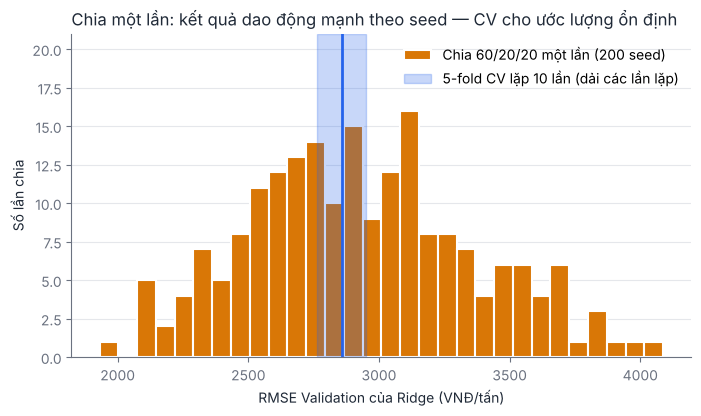

Đã lưu: hinh_anh_60_20_20/Hinh_A2_Mo_hinh_thang_va_alpha_200_seed.png


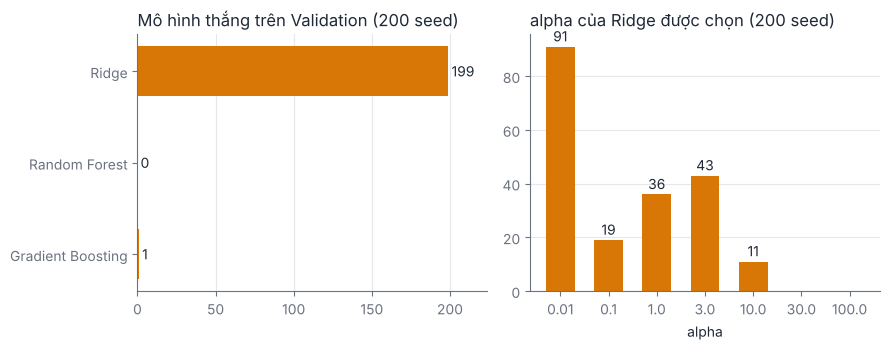

Đã lưu: hinh_anh_60_20_20/Hinh_A3_RMSE_Test_200_seed.png


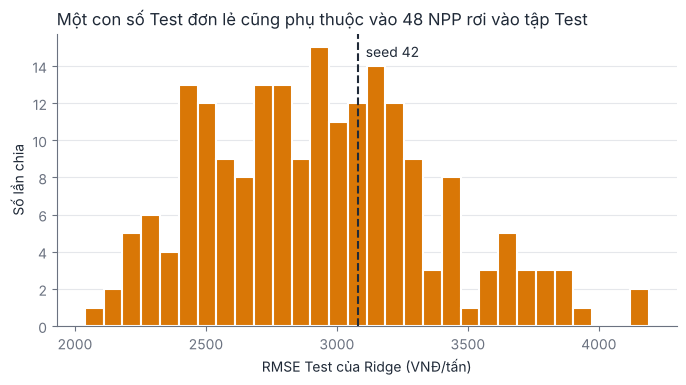

In [6]:
INK, MUTED, GRID = "#1f2937", "#6b7280", "#e5e7eb"
C_A, C_B = "#d97706", "#2563eb"      # cam = chia 1 lần (60/20/20), xanh = CV
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})

# Hình 1: phân phối RMSE Validation của Ridge qua 200 lần chia 60/20/20 vs dải kết quả CV
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(rep.val_Ridge, bins=30, color=C_A, edgecolor="white", linewidth=1.5, label="Chia 60/20/20 một lần (200 seed)")
ax.axvspan(ridge_reps.min(), ridge_reps.max(), color=C_B, alpha=0.25, label="5-fold CV lặp 10 lần (dải các lần lặp)")
ax.axvline(cv_res["Ridge"]["RMSE CV (TB 50 fold)"], color=C_B, lw=2)
ax.set_xlabel("RMSE Validation của Ridge (VNĐ/tấn)"); ax.set_ylabel("Số lần chia")
ax.set_title("Chia một lần: kết quả dao động mạnh theo seed — CV cho ước lượng ổn định", color=INK, loc="left")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25); ax.grid(axis="y", color=GRID); ax.set_axisbelow(True); ax.legend(frameon=False, loc="upper right")
save_fig(fig, "Hinh_A1_RMSE_Validation_200_seed_vs_CV"); plt.show()

# Hình 2: mô hình thắng và alpha được chọn qua 200 lần chia
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
wins = rep.mo_hinh_thang.value_counts().reindex(ORDER, fill_value=0)
axs[0].barh(wins.index[::-1], wins.values[::-1], color=C_A, height=0.55)
for i, v in enumerate(wins.values[::-1]): axs[0].text(v + 2, i, str(v), va="center", color=INK)
axs[0].set_title("Mô hình thắng trên Validation (200 seed)", color=INK, loc="left"); axs[0].set_xlim(0, N_SEEDS * 1.12)
al = rep.alpha_chon.value_counts().reindex([p["alpha"] for p in grids["Ridge"]], fill_value=0)
axs[1].bar([str(a) for a in al.index], al.values, color=C_A, width=0.6)
for i, v in enumerate(al.values):
    if v: axs[1].text(i, v + 2, str(v), ha="center", color=INK)
axs[1].set_title("alpha của Ridge được chọn (200 seed)", color=INK, loc="left"); axs[1].set_xlabel("alpha")
for a in axs: a.grid(axis="x" if a is axs[0] else "y", color=GRID); a.set_axisbelow(True)
fig.tight_layout(); save_fig(fig, "Hinh_A2_Mo_hinh_thang_va_alpha_200_seed"); plt.show()

# Hình 3: RMSE Test của Ridge cũng phụ thuộc vào lần chia
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(rep.test_Ridge, bins=30, color=C_A, edgecolor="white", linewidth=1.5)
ax.axvline(rep.loc[rep.seed == SEED, "test_Ridge"].iloc[0], color=INK, lw=1.5, ls="--")
ax.text(rep.loc[rep.seed == SEED, "test_Ridge"].iloc[0], ax.get_ylim()[1] * 0.92, "  seed 42", color=INK)
ax.set_xlabel("RMSE Test của Ridge (VNĐ/tấn)"); ax.set_ylabel("Số lần chia")
ax.set_title("Một con số Test đơn lẻ cũng phụ thuộc vào 48 NPP rơi vào tập Test", color=INK, loc="left")
ax.grid(axis="y", color=GRID); ax.set_axisbelow(True)
save_fig(fig, "Hinh_A3_RMSE_Test_200_seed"); plt.show()

## Bước 6 – Tổng hợp và kết luận

In [7]:
cv_r = cv_res["Ridge"]
print("=" * 72)
print("CÁCH A – 60/20/20 MỘT LẦN (seed 42)")
print(f"  Mô hình chọn: {chosen_A} | RMSE Validation {summary_A.set_index('Mô hình').loc[chosen_A, 'RMSE Validation']:.1f}"
      f" | RMSE Test {summary_A.set_index('Mô hình').loc[chosen_A, 'RMSE Test']:.1f}")
print("\nCÁCH A LẶP 200 SEED – Ridge")
print(f"  RMSE Validation: {rep.val_Ridge.min():.0f} → {rep.val_Ridge.max():.0f}"
      f"  (P5 {rep.val_Ridge.quantile(.05):.0f}, trung vị {rep.val_Ridge.median():.0f}, P95 {rep.val_Ridge.quantile(.95):.0f})")
print(f"  RMSE Test:       {rep.test_Ridge.min():.0f} → {rep.test_Ridge.max():.0f}")
print(f"  Ridge thắng {int((rep.mo_hinh_thang == 'Ridge').sum())}/{N_SEEDS} lần; "
      f"alpha được chọn thay đổi giữa {rep.alpha_chon.nunique()} giá trị")
print("\nCÁCH B – 80/20 + 5-FOLD CV LẶP 10 LẦN – Ridge")
print(f"  RMSE CV {cv_r['RMSE CV (TB 50 fold)']:.0f} ± {cv_r['SD']:.0f}; trung bình các lần lặp "
      f"{cv_r['TB lần lặp – min']:.0f} → {cv_r['TB lần lặp – max']:.0f}")
w_a = rep.val_Ridge.quantile(.95) - rep.val_Ridge.quantile(.05)
w_b = cv_r['TB lần lặp – max'] - cv_r['TB lần lặp – min']
print(f"\n→ Độ rộng dao động (P5–P95) khi chia 1 lần ≈ {w_a:.0f} VNĐ/tấn, "
      f"gấp ~{w_a / w_b:.0f} lần dải của CV ({w_b:.0f} VNĐ/tấn).")
print("=" * 72)

CÁCH A – 60/20/20 MỘT LẦN (seed 42)
  Mô hình chọn: Ridge | RMSE Validation 2945.5 | RMSE Test 3080.3

CÁCH A LẶP 200 SEED – Ridge
  RMSE Validation: 1931 → 4088  (P5 2260, trung vị 2900, P95 3676)
  RMSE Test:       2038 → 4190
  Ridge thắng 199/200 lần; alpha được chọn thay đổi giữa 5 giá trị

CÁCH B – 80/20 + 5-FOLD CV LẶP 10 LẦN – Ridge
  RMSE CV 2859 ± 512; trung bình các lần lặp 2763 → 2951

→ Độ rộng dao động (P5–P95) khi chia 1 lần ≈ 1417 VNĐ/tấn, gấp ~8 lần dải của CV (188 VNĐ/tấn).


**Cách đọc kết quả (ghi vào báo cáo mục 5.5.1):**

1. **Mô hình được chọn không đổi.** Ridge thắng ở cả hai cách chia. Việc đổi sang CV *không* nhằm thay đổi kết luận, mà để kết luận **đáng tin hơn**.
2. **Con số đánh giá thì đổi theo "may rủi".** Khi chia 60/20/20 một lần, RMSE Validation của cùng một mô hình có thể chênh nhau khoảng gấp đôi tùy seed. Với CV, các lần lặp chỉ dao động vài chục đến vài trăm VNĐ/tấn.
3. **Siêu tham số cũng không ổn định.** Giá trị `alpha` được chọn thay đổi theo lần chia. Lý do là Validation chỉ có 48 NPP, quá ít để phân biệt các mức tinh chỉnh gần nhau.
4. **Tập Test vẫn cần thiết nhưng phải kèm khoảng tin cậy.** RMSE Test cũng dao động theo 48 NPP rơi vào tập Test. Vì vậy báo cáo chính thức ghi RMSE Test kèm khoảng tin cậy bootstrap 90%.

→ Với 240 NPP, **80/20 + 5-fold CV lặp 10 lần** là lựa chọn phù hợp: dùng hết 192 NPP cho việc chọn mô hình và vẫn giữ 48 NPP độc lập để báo cáo kết quả cuối cùng.